# FAYE Marie Pierre Gnilane Ndew
# 12213642

# **PLUS PROCHE VOISIN**
## 1) fonction ppv 
Tout d'abord elle reçoit en entrée des données X et des étiquettes Y. PPV va d'abord calculer la distance euclidienne entre chaque paire de données et la mettre dans une matrice distance en utilisant la fonction `metrics.pairwise.euclidean_distances`.Ensuite on remplace les distances d'un point par lui-même avec l'infini vu qu'un point est toujours à une distance 0 de lui-même, avant de chercher le minimum. Puis elle compare chaque distance pour chaque ligne et trouve l'indice du minimum avec la fonction `argmin` enfin elle indexe Y avec les indices du ppv et renvoie un tableau d'etiquettes de la classe du plus proche voisin.

In [1]:
import numpy as np
from sklearn import *
import matplotlib.pyplot as plt

def PPV(X,Y):
    
    distance = metrics.pairwise.euclidean_distances(X,X)
    np.fill_diagonal(distance, val= np.inf)
    indice_du_ppv = np.argmin(distance, axis = 1)
    res = Y[indice_du_ppv]
    
    return res

iris = datasets.load_iris()
PPV(iris.data,iris.target)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [2]:
iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

## 2) Modification de la fonction pour calculer et renvoyer l'erreur de prédiction

Pour calculer le taux d'erreur, on compare, pour chaque point, l'étiquette prédite par l'algorithme à son étiquette réelle. On obtient ainsi un tableau qui indique, point par point, si la prédiction est fausse. La moyenne de ce tableau donne la proportion de points mal classés, c'est-à-dire le taux d'erreur, que l'on multiplie par 100 pour l'exprimer en pourcentage. Chaque point est classé à partir des autres points uniquement, sans se servir de lui-même, ce qui permet d'obtenir une estimation honnête de l'erreur.

In [3]:
def PPV_modifie(X,Y):
    
    distance = metrics.pairwise.euclidean_distances(X,X)
    np.fill_diagonal(distance, val= np.inf)
    indice_du_ppv = np.argmin(distance, axis = 1)
    res = Y[indice_du_ppv]
    diff = (res != Y)
    moyenne = diff.mean()
    taux_d_err = moyenne*100
    
    return taux_d_err

## 3) Test sur Iris

In [4]:
PPV_modifie(iris.data,iris.target)

np.float64(4.0)

Le taux d'erreur est de 4% : sur 150 étiquettes 6 ont été mal prédites.

## 4) Test avec la fonction des K plus proches voisins 

In [5]:
model = neighbors.KNeighborsClassifier(1)
model.fit(iris.data, iris.target)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [6]:
predict = model.predict(iris.data)
taux_d_err1 = ((predict != iris.target).mean())*100
print(taux_d_err1)

0.0


Les résultats sont différents. Ici le taux d'erreurs est de 0% car le modèle a mémorisé tous les points d'iris pendant l'entrainement; il a appris par coeur. Quand on lui demande de prédire un point, il cherche son plus proche voisin dans les données mémorisées et il trouve ce point lui-même à une distance 0. Il recopie donc sa propre étiquette qui est forcément la bonne. 
Or ce que `PPV_modifie()` faisait est différent elle interdisait à chaque point d'être son propre voisin en mettant l'infini sur la diagonale. Chaque point était donc classé grâce aux autres uniquement.
Voila pourquoi les 4% sont une estimation de l'erreur de généralisation alors que 0% est une erreur d'apprentissage.

**Test avec d'autres valeurs K**

In [7]:
model1 = neighbors.KNeighborsClassifier(5)
model1.fit(iris.data, iris.target)
predict1 = model1.predict(iris.data)
taux_d_err2 = ((predict1 != iris.target).mean())*100
print(taux_d_err2)

3.3333333333333335


In [8]:
models = neighbors.KNeighborsClassifier(10)
models.fit(iris.data, iris.target)
predicts = models.predict(iris.data)
taux_d_errs = ((predicts != iris.target).mean())*100
print(taux_d_errs)

2.0


In [9]:
model2 = neighbors.KNeighborsClassifier(30)
model2.fit(iris.data, iris.target)
predict2 = model2.predict(iris.data)
taux_d_err3 = ((predict2 != iris.target).mean())*100
print(taux_d_err3)

4.666666666666667


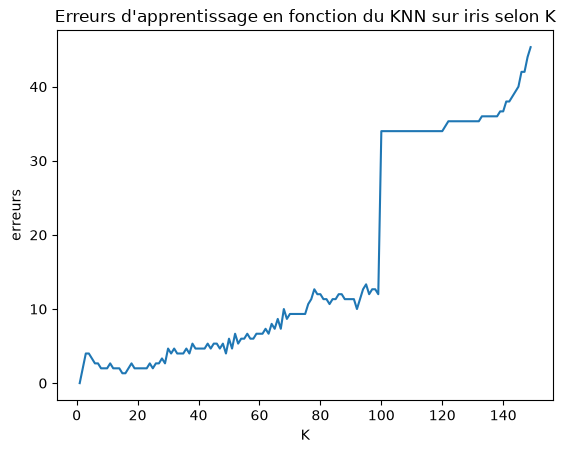

In [10]:
K = range(1,150)
err = []
for i in K:
    mod = neighbors.KNeighborsClassifier(i)
    mod.fit(iris.data, iris.target)
    pred = mod.predict(iris.data)
    tde = ((pred != iris.target).mean())*100
    err.append(tde)

plt.plot(K,err)
plt.xlabel("K")
plt.ylabel("erreurs")
plt.title("Erreurs d'apprentissage en fonction du KNN sur iris selon K")
plt.show()

Chaque espèce compte 50 points. Pour un point de setosa, avec 100 votants on sait que 50 sont de setosa et les autres de versicolor. Avec 101 votants il a toujours 50 voisins setosa au maximum mais 51 viennent d'autres espèces. Donc avec 51 votes contre 50 setosa devient minoritaire et perd le vote. De ce fait les 50 points de la première espèce deviennent mal classés et on peut voir que l'erreur sur le graphe atteint environ 34%. C'est un cas extrême de sous-apprentissage.

## 5) BONUS
`PPV_k()` prend en entrée un nombre K de voisins, des données X et les étiquettes Y de classe de X. On retrouve les mêmes premières étapes que `PPV()`: calculer la distance entre les paires de données, ensuite mettre la diagonale à l'infini pour qu'un point ne puisse pas être son propre voisin. Ici on va prendre les K premières colonnes de `indice_du_ppv` après avoir trié les indices avec `argsort`. Puis on indexe Y avec les K indices. Ensuite on va voter (pour chaque point on compte les voix de chaque classe, puis on retient celle qui en a le plus) en parcourant `index` pour trouver la classe majoritaire qui est renvoyée à la fin.

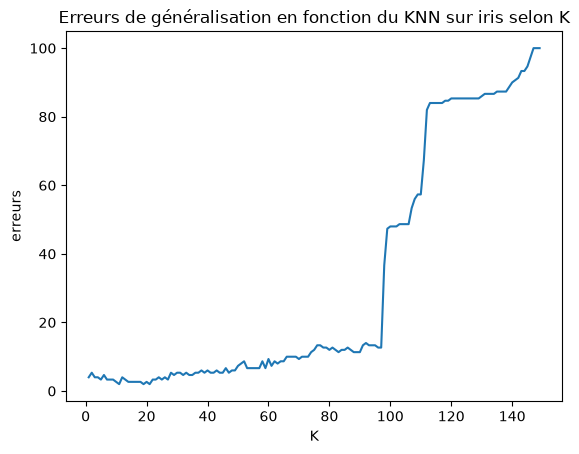

In [11]:
def PPV_k(K,X,Y):
    
    distance = metrics.pairwise.euclidean_distances(X,X)
    np.fill_diagonal(distance, val= np.inf)
    indice_du_ppv = np.argsort(distance, axis = 1)
    slicing = indice_du_ppv[:,:K]
    index = Y[slicing]

    liste = []
    for i in index:
        comptage = np.bincount(i)
        classe_max = np.argmax(comptage)
        liste.append(classe_max)
    classe_majo = np.array(liste)

    return classe_majo

K = range(1,150)
err = []
for i in K:
    mod = PPV_k(i,iris.data,iris.target)
    tde = ((mod != iris.target).mean())*100
    err.append(tde)

plt.plot(K,err)
plt.xlabel("K")
plt.ylabel("erreurs")
plt.title("Erreurs de généralisation en fonction du KNN sur iris selon K")
plt.show()

Ce graphe représente l'erreur de généralisation du KNN sur iris, estimée en leave-one-out, en fonction du nombre de voisins K : elle reste faible (autour de 2 à 4 %) pour les petites valeurs de K, puis augmente progressivement avant de bondir brutalement au-delà de K = 99, signe d'un fort sous-apprentissage.Comparée à l'erreur d'apprentissage, l'erreur de généralisation est plus élevée pour les petites valeurs de K (4 % contre 0 % pour K = 1), car le point à classer ne peut plus voter pour lui-même, et ses sauts surviennent plus tôt et sont plus marqués, jusqu'à atteindre 100 % d'erreur pour K = 149

# **CLASSIFIEUR BAYESIAN NAÏF**
# 1) fonction CBN
La fonction `CBN(X, Y)` affecte chaque donnée à la classe la plus probable. Pour chaque classe, elle calcule le barycentre et la probabilité a priori P(ωₖ) (proportion de données de la classe). Pour chaque donnée, P(xᵢ/ωₖ) est obtenue à partir de l’écart entre xᵢ et le barycentre, divisé par la somme des écarts sur toutes les classes ; nous utilisons 1 moins ce rapport pour qu’une donnée proche d’un barycentre ait une forte probabilité. Ces probabilités sont multipliées sur les variables, puis par P(ωₖ), et la classe au score maximal est retenue avec argmax

In [12]:
def CBN(X,Y):
    
    class_unik = np.unique(Y)

    ligne_X = []
    prob = []
    for i in class_unik: 
        select = X[(Y==i)]
        nbre_select = len(select)
        bar = np.mean(select, axis=0)
        ligne_X.append(bar)
        prob1 =  nbre_select/len(X)
        prob.append(prob1)
    
    ligne_X = np.asarray(ligne_X)
    prob = np.asarray(prob)

    pred=[]
    for x in X:
        distance = abs(x - ligne_X)
    
        proba = []
    
        for i in distance : 
            proba_i = 1 - i/sum(distance)
            proba.append(proba_i)
        
        proba_final = np.asarray(proba)
        res = np.prod(proba_final, axis = 1)

        res_final = res*prob
        pred.append(class_unik[np.argmax(res_final)])

    pred = np.asarray(pred)
    return pred

## 2) CBN_modifie() 

In [13]:
def CBN_modifie(X,Y):
    
    class_unik = np.unique(Y)

    ligne_X = []
    prob = []
    for i in class_unik: 
        select = X[(Y==i)]
        nbre_select = len(select)
        bar = np.mean(select, axis=0)
        ligne_X.append(bar)
        prob1 =  nbre_select/len(X)
        prob.append(prob1)
    
    ligne_X = np.asarray(ligne_X)
    prob = np.asarray(prob)

    pred=[]
    for x in X:
        distance = abs(x - ligne_X)
    
        proba = []
    
        for i in distance : 
            proba_i = 1 - i/sum(distance)
            proba.append(proba_i)
        
        proba_final = np.asarray(proba)
        res = np.prod(proba_final, axis = 1)

        res_final = res*prob
        pred.append(class_unik[np.argmax(res_final)])
    
    pred = np.asarray(pred)
    err = (pred != Y)
    taux_d_err = (err.mean())*100
    return taux_d_err

In [14]:
CBN(iris.data,iris.target)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 2, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 2,
       2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2])

In [15]:
CBN_modifie(iris.data,iris.target)

np.float64(12.666666666666668)

Sur iris, le classifieur bayésien naïf obtient environ 12,67 % d’erreur (19 points mal classés sur 150), contre 4 % pour le plus proche voisin. Setosa est parfaitement reconnue, car elle est bien séparée des autres espèces. Toutes les erreurs sont des confusions entre versicolor et virginica, qui se chevauchent. Cette méthode résume chaque classe par un seul point, son barycentre : une fleur située en bordure de son groupe, du côté de l’autre espèce, peut alors se retrouver plus proche du barycentre de la mauvaise classe. Le KPPV, qui s’appuie sur les points voisins individuels, gère mieux ces zones de chevauchement.

## 3) Application sur iris avec la fonction de sk_learn

In [16]:
mod = naive_bayes.GaussianNB()
mod.fit(iris.data,iris.target)
prediction = mod.predict(iris.data)
tde = ((prediction!= iris.target).mean())*100
tde

np.float64(4.0)

GaussianNB obtient 4 % d’erreur contre environ 12,67 % pour notre implémentation, car il modélise chaque variable par une loi normale qui tient compte de la dispersion des classes, alors que notre méthode ne s’appuie que sur la distance aux barycentres.

## 4) BONUS

In [17]:
def CBN_gauss(X,Y):
    
    class_unik = np.unique(Y)

    ligne_X = []
    prob = []
    ecart = []
    for i in class_unik: 
        select = X[(Y==i)]
        nbre_select = len(select)
        bar = np.mean(select, axis=0)
        ecart_type = select.std(0)
        ligne_X.append(bar)
        prob1 =  nbre_select/len(X)
        prob.append(prob1)
        ecart.append(ecart_type)
    
    ligne_X = np.asarray(ligne_X)
    prob = np.asarray(prob)
    ecart = np.asarray(ecart)

    pred=[]
    for x in X:
        densite = 1/(ecart*np.sqrt(2*np.pi)) * np.exp((-(x-ligne_X)**2)/(2*ecart**2))
        res = (np.prod(densite, axis = 1))*prob
        pred.append(class_unik[np.argmax(res)])
        

    pred = np.asarray(pred)
    err = (pred != Y)
    taux_d_err = (err.mean())*100
    return taux_d_err

In [18]:
CBN_gauss(iris.data,iris.target)

np.float64(4.0)

Testée sur iris, la version gaussienne de CBN obtient 4 % d’erreur, soit le même résultat que GaussianNB de sklearn, ce qui valide notre implémentation.